# 03 — Cox Proportional Hazards Baseline: C-MAPSS FD001

See `docs/project_brief.md` Section 4 for why Cox PH is included at all: it's
the reference standard in survival analysis, gives directly interpretable
hazard ratios, and — most importantly for this notebook — gives us a
*diagnostic surface* (Schoenfeld residuals) for testing whether the
proportional-hazards assumption actually holds for this data. If it doesn't,
that's not a failure of this notebook; it's evidence for why Random Survival
Forest (Phase 5) is a better-justified deployment candidate than "we tried
Cox and it worked well enough."

This notebook:
1. Rebuilds Phase 2's engineered train survival table (every row `event=1`
   at its remaining life capped at 125 -- see `labeling.py`)
2. Splits by **engine**, not by row (see `models.py` for why a row-level
   split would leak)
3. Picks a deliberately curated, interpretable feature subset for Cox
   (not all 205 engineered columns — see rationale below)
4. Fits a (regularized) Cox PH model, reports hazard ratios with standard
   errors clustered by engine
5. Reports concordance index on the held-out engines
6. Runs the Schoenfeld-residuals proportional-hazards check and interprets
   which covariates violate the assumption


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path("..") / "src"))
from turbofan_rul import data_loading, features, labeling, models, plotting

plotting.style()
SUBSET = "FD001"
CAP = 125
DATA_DIR = Path("..") / "data" / "raw"
PROCESSED_DIR = Path("..") / "data" / "processed"
MODELS_DIR = Path("..") / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Rebuild the train survival table

Re-running Phase 1 + 2's pipeline here (rather than only reading a cached
parquet) so this notebook works standalone on a fresh checkout — the
functions are identical to `02_feature_engineering.ipynb`, called from the
same `src/` package.

In [2]:
data_loading.download_cmapss(SUBSET, data_dir=DATA_DIR)
cmapss = data_loading.load_subset(SUBSET, data_dir=DATA_DIR)
kept_sensors = features.load_kept_sensors(PROCESSED_DIR / f"{SUBSET.lower()}_sensor_selection.json")

train_survival = labeling.build_train_survival_frame(cmapss.train, cap=CAP)
train_survival = features.build_feature_matrix(train_survival, kept_sensors=kept_sensors)

print(train_survival.shape)

(20631, 234)


## 2. Engine-level train/validation split

In [3]:
cox_train_df, cox_val_df = models.train_val_split_by_engine(
    train_survival, val_fraction=0.2, random_state=42
)
print(f"train: {cox_train_df.unit_number.nunique()} engines, {len(cox_train_df)} rows")
print(f"val:   {cox_val_df.unit_number.nunique()} engines, {len(cox_val_df)} rows")
assert set(cox_train_df.unit_number).isdisjoint(set(cox_val_df.unit_number))
print("OK: no engine appears in both splits.")

train: 80 engines, 16779 rows


val:   20 engines, 3852 rows
OK: no engine appears in both splits.


## 3. Feature subset for Cox PH

Cox PH is being used here as an **interpretable baseline**, not asked to
consume the full 205-column engineering output from Phase 2 — most of those
columns are near-duplicates of each other by construction (a sensor's
roll5/roll15/roll30 means are highly correlated with one another), and
fitting Cox on all of them would produce hazard ratios that are technically
computable but not meaningfully interpretable (that's exactly the
multicollinearity risk flagged as a Cox-specific concern back in Phase 1's
EDA). Random Survival Forest in Phase 5, which doesn't share this
interpretability goal, gets the full feature set.

One representative window (`roll15`) per sensor, mean + slope, is used here
— roll15 sits between the noisier `roll5` and the more lagged `roll30`, and
mean+slope captures both level and trend without redundant window
duplication.

In [4]:
cox_feature_cols = ["cycle_count"]
for sensor in kept_sensors:
    cox_feature_cols += [f"{sensor}_roll15_mean", f"{sensor}_roll15_slope"]

print(f"{len(cox_feature_cols)} features selected for Cox PH: {cox_feature_cols}")

25 features selected for Cox PH: ['cycle_count', 'sensor_2_roll15_mean', 'sensor_2_roll15_slope', 'sensor_3_roll15_mean', 'sensor_3_roll15_slope', 'sensor_4_roll15_mean', 'sensor_4_roll15_slope', 'sensor_7_roll15_mean', 'sensor_7_roll15_slope', 'sensor_9_roll15_mean', 'sensor_9_roll15_slope', 'sensor_11_roll15_mean', 'sensor_11_roll15_slope', 'sensor_12_roll15_mean', 'sensor_12_roll15_slope', 'sensor_14_roll15_mean', 'sensor_14_roll15_slope', 'sensor_15_roll15_mean', 'sensor_15_roll15_slope', 'sensor_17_roll15_mean', 'sensor_17_roll15_slope', 'sensor_20_roll15_mean', 'sensor_20_roll15_slope', 'sensor_21_roll15_mean', 'sensor_21_roll15_slope']


## 4. Standardize + fit

Standardizing lets the hazard ratios be read on a common scale ("one
standard deviation increase in this feature multiplies the hazard by
exp(coef)"), and a ridge penalizer is applied to keep coefficients stable
under the residual collinearity that a curated-but-not-orthogonal feature
set still has (see `models.py` for why the penalizer isn't left at zero).

**Standard errors are clustered by engine** (`cluster_col="unit_number"`).
The ~17k training rows come from only 80 engines, and consecutive cycles of
one engine are strongly correlated. Default Cox standard errors treat every
row as an independent subject, which makes them far too small and the
p-values far too confident. Clustering by engine gives robust (sandwich)
standard errors that account for this. The coefficients and predictions are
identical either way; only the uncertainty changes.

In [5]:
cox_train_scaled, cox_val_scaled, cox_scaler = models.standardize_features(
    cox_train_df, cox_val_df, cox_feature_cols
)

cox_model = models.fit_cox_ph(cox_train_scaled, cox_feature_cols, penalizer=0.1,
                              cluster_col="unit_number")
models.save_model(cox_model, MODELS_DIR / "cox_ph_fd001.joblib")
print("Fit complete.")

Fit complete.


## 5. Hazard ratios

`exp(coef) > 1` means the feature *increases* the hazard (shortens
remaining life) as it increases; `< 1` means it's protective. Sorted by
p-value (from the engine-clustered standard errors) so the features with
the strongest evidence are at the top.

,coef,exp(coef),p,exp(coef) lower 95%,exp(coef) upper 95%
covariate,,,,,
sensor_20_roll15_slope,-0.067067,0.935133,3.612252e-11,0.916745,0.953889
sensor_14_roll15_mean,0.247732,1.281116,5.612907e-09,1.178707,1.392424
sensor_15_roll15_slope,0.042053,1.042950,7.277812e-08,1.027106,1.059039
sensor_4_roll15_slope,0.055805,1.057391,2.274721e-07,1.035279,1.079976
sensor_11_roll15_mean,0.118962,1.126327,3.897452e-07,1.075740,1.179293
sensor_2_roll15_slope,0.043725,1.044696,4.234677e-07,1.027144,1.062547
sensor_9_roll15_mean,0.238506,1.269351,1.543357e-06,1.151690,1.399034
sensor_4_roll15_mean,0.187396,1.206105,5.270032e-06,1.112644,1.307416
sensor_7_roll15_slope,-0.047417,0.953690,2.958297e-05,0.932703,0.975148


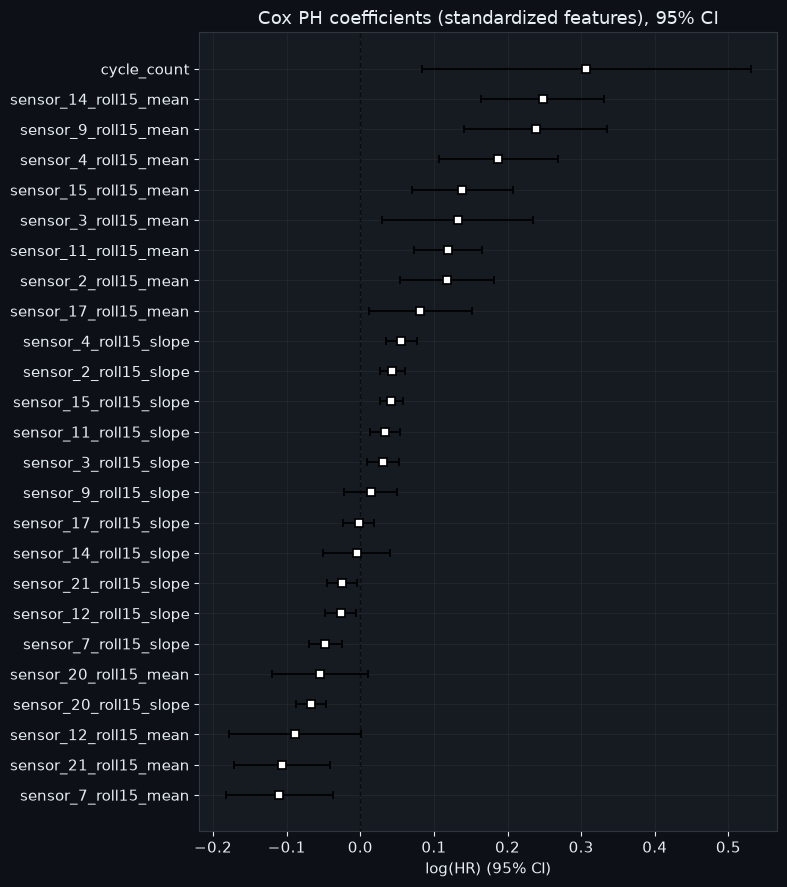

In [6]:
summary = cox_model.summary.sort_values("p")
display(summary[["coef", "exp(coef)", "p", "exp(coef) lower 95%", "exp(coef) upper 95%"]].head(15))

fig, ax = plt.subplots(figsize=(8, 9))
cox_model.plot(ax=ax)
ax.set_title("Cox PH coefficients (standardized features), 95% CI")
plt.tight_layout()
plt.show()

## 6. Concordance index on held-out engines

Both numbers below are lifelines' row-level Harrell's C: every row of the
20 validation engines is a separate subject, and C
measures how well the model ranks those rows by time to failure. That makes
it comparable to the validation C reported for Weibull AFT (Phase 4) and RSF
(Phase 5) on the same split -- but **not** to the engine-level C computed on
the official 100-engine test set in later notebooks, which is a different
quantity on different data.

In [7]:
train_cindex = cox_model.concordance_index_
val_cindex = cox_model.score(cox_val_scaled, scoring_method="concordance_index")

print(f"Train concordance index: {train_cindex:.5f}")
print(f"Val (held-out engines) concordance index: {val_cindex:.5f}   <- the number to compare across models")
print("\n0.5 = random ranking, 1.0 = perfect risk ranking.")

Train concordance index: 0.86981
Val (held-out engines) concordance index: 0.87480   <- the number to compare across models

0.5 = random ranking, 1.0 = perfect risk ranking.


## 7. Proportional-hazards assumption check (Schoenfeld residuals)

This is the diagnostic that actually justifies (or doesn't) using Cox PH at
all. A covariate that fails this test has a hazard *ratio* that isn't
constant over time — which, physically, is exactly what we'd expect for a
degrading mechanical system: a sensor's effect on failure risk plausibly
intensifies as an engine nears end-of-life, rather than staying constant
across an engine's whole lifetime. Finding violations here isn't a bug in
this notebook — it's evidence for the model-ladder approach in the project
brief, motivating Weibull AFT (Phase 4) and especially Random Survival
Forest (Phase 5), neither of which assumes constant proportional hazards.

**How much weight to put on the count below.** The test treats each of the
~17k training rows as an independent subject, but they come from only 80
engines. With that much (pseudo-)replication, even a small, practically
unimportant drift in a hazard ratio comes out "significant" at p < 0.05, so
the number of failing covariates overstates the evidence. Read it as a
direction -- the proportional-hazards assumption is not a good description
of this data -- not as a precise count. The test statistics (larger =
stronger time-dependence) are more informative than the 0.05 cut-off.

In [8]:
from lifelines.statistics import proportional_hazard_test

# Must pass exactly the columns the model was fit on: the fitted covariates,
# duration/event, and the cluster column (the model was fit with
# cluster_col="unit_number", and lifelines expects to find it again). Passing
# the full 234-column frame causes an internal shape mismatch, since lifelines
# expects the covariate matrix to align one-for-one with the coefficient vector.
assumption_check_df = cox_train_scaled[cox_feature_cols + ["duration", "event", "unit_number"]]

ph_test = proportional_hazard_test(cox_model, assumption_check_df, time_transform="rank")
ph_summary = ph_test.summary.sort_values("p")
display(ph_summary)

n_fail = (ph_summary["p"] < 0.05).sum()
print(f"\n{n_fail} / {len(ph_summary)} covariates FAIL the proportional-hazards "
      f"assumption at p < 0.05 (an overstated count -- see the note above).")

,test_statistic,p,-log2(p)
sensor_20_roll15_slope,40.462174,2.004595e-10,32.215970
sensor_15_roll15_slope,30.593918,3.180893e-08,24.905993
sensor_2_roll15_mean,26.925167,2.114870e-07,22.172928
sensor_2_roll15_slope,19.831489,8.457782e-06,16.851289
sensor_11_roll15_mean,17.209837,3.346987e-05,14.866778
sensor_7_roll15_slope,16.991422,3.754908e-05,14.700863
sensor_4_roll15_slope,16.260495,5.520296e-05,14.144895
sensor_11_roll15_slope,7.838633,5.114128e-03,7.611296
sensor_15_roll15_mean,6.871564,8.757796e-03,6.835216
sensor_7_roll15_mean,6.783310,9.201409e-03,6.763929



14 / 25 covariates FAIL the proportional-hazards assumption at p < 0.05 (an overstated count -- see the note above).


## Summary

- Cox PH gives interpretable hazard ratios and a usable held-out concordance
  index, but is fit on a deliberately curated feature subset, not the full
  engineered feature space.
- Hazard-ratio uncertainty uses standard errors clustered by engine, since
  rows within an engine are not independent.
- The Schoenfeld residual test above (output printed, not silently ignored)
  shows that the proportional-hazards assumption doesn't describe this data
  well. The exact count of failing covariates is inflated by treating
  correlated rows as independent (see Section 7), but the direction is
  clear, and it's carried forward as the stated justification for trying
  Weibull AFT and Random Survival Forest next, rather than those being
  included "just to have more models to compare."